# TPS with Descriptor Storage - Toy System

This notebook demonstrates how to use the descriptor storage functionality with a toy potential system during TPS sampling.

Key features:
- Incremental descriptor storage during sampling
- Automatic handling of CV shapes and names
- No manual index tracking needed

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import openpathsampling as paths
from pathlib import Path

# Import from ops-setup
from ops_setup.systems.examples.toy_systems import ToyTPSSetup
from ops_setup.descriptor_storage import DescriptorStorage, sampling_descriptor_manager

## 1. Create TPS Setup

In [2]:
# Setup TPS for wolfe-quapp potential (2D system with two minima)
tps_setup = ToyTPSSetup(
    potential_name='wolfe-quapp',
    potential_kwargs={'n_harmonics': 0, 'rotation_degrees': 0, 'scale': 2},
    integrator_params={
        'dt': 0.05,
        'temperature': 1.0,
        'gamma': 5
    }
)

print(f"System: {tps_setup.system_name}")
print(f"MD Engine: {tps_setup.md_engine.name}")
print(f"States: {tps_setup.states}")

Setting up Langevin BAOAB integrator for toy system...
seed used for harmonic oscilattors 123
pot dimensions without oscillators: 2
harmonic oscillators omegas:
array([0., 0.])
Setting up Langevin BAOAB integrator for toy system...
Setting up toy engine for wolfe-quapp...
Creating snapshot template for toy system...
Defining states for wolfe-quapp...
System: wolfe-quapp
MD Engine: [ToyEngine]
States: (<openpathsampling.volume.CVDefinedVolume object at 0x7efb3c211350>, <openpathsampling.volume.CVDefinedVolume object at 0x7efb3c2bd710>)


## 2. Define Collective Variables

For the toy system, we'll use x and y coordinates as descriptors.

In [3]:
# Define simple CVs for x and y coordinates
cv_x = paths.CoordinateFunctionCV(
    name="x_coord",
    f=lambda snap: snap.coordinates[0][0]
)

cv_y = paths.CoordinateFunctionCV(
    name="y_coord", 
    f=lambda snap: snap.coordinates[0][1]
)

# Test on template
print(f"Template x: {cv_x(tps_setup.template)}")
print(f"Template y: {cv_y(tps_setup.template)}")

Template x: 0.5
Template y: 0.5


## 3. Create Initial Trajectory

In [4]:
# Set engine for path movers
paths.PathMover.engine = tps_setup.md_engine

# Create initial trajectory from state A to state B
pes = tps_setup.pes
init_traj = paths.Trajectory(pes.simple_initial_path(100, tps_setup.md_engine))

print(f"Initial trajectory length: {len(init_traj)} snapshots")
print(f"First frame coordinates: {init_traj[0].coordinates}")
print(f"Last frame coordinates: {init_traj[-1].coordinates}")

Initial trajectory length: 100 snapshots
First frame coordinates: [[-1.15  1.5 ]]
Last frame coordinates: [[ 1.127 -1.47 ]]


## 4. Setup TPS Network and Move Scheme

In [5]:
# Create selector
tps_setup._create_selector()

# Create TPS network
network = paths.TPSNetwork.from_states_all_to_all(tps_setup.states)
print(f"Network: {network}")

# Create move scheme
move_scheme = tps_setup.create_move_scheme(network, scheme_type="TwoWay")
print(f"Move scheme: {move_scheme}")

Network: <openpathsampling.high_level.network.TPSNetwork object at 0x7efb025944d0>
Move scheme: <openpathsampling.high_level.move_scheme.MoveScheme object at 0x7efb02776b90>


## 5. Initialize OPS Storage and Sampler

In [6]:
# Create OPS storage
storage_file = "storages/toy_tps_descriptor_test.nc"
# create storages directory if it doesn't exist
Path("storages").mkdir(exist_ok=True)


storage = paths.Storage(storage_file, "w", template=tps_setup.template)

# Save setup components
storage.save(tps_setup.md_engine)
storage.save(tps_setup.template)
storage.save(move_scheme)
storage.save(network)

# Create initial conditions and sampler
initial_conditions = move_scheme.initial_conditions_from_trajectories(init_traj)
initial_conditions.sanity_check()
print("Initial conditions sanity check passed!")

sampler = paths.PathSampling(storage, move_scheme, initial_conditions)
print(f"Sampler ready. Storage: {storage_file}")

No missing ensembles.
No extra ensembles.
Initial conditions sanity check passed!
Sampler ready. Storage: storages/toy_tps_descriptor_test.nc


## 6. Initialize Descriptor Storage

Store the initial trajectory's descriptors first.

In [7]:
descriptor_storage_path = Path("storages/toy_descriptor_storage_test")

# Store initial trajectory
with DescriptorStorage(descriptor_storage_path, mode='w', method_type='TPS') as desc_storage:
    desc_storage.add_trajectory(
        set_name='TPS',
        interface_value=0.0,
        descriptors={
            'x_coord': np.asarray(cv_x(init_traj)).reshape(-1, 1),
            'y_coord': np.asarray(cv_y(init_traj)).reshape(-1, 1),
        },
        n_points=len(init_traj),
        storage_index=0
    )

print(f"Initial trajectory stored with {len(init_traj)} points")

Initial trajectory stored with 100 points


## 7. Run TPS with Incremental Descriptor Storage

Use the new `sampling_descriptor_manager` to automatically handle descriptor storage during sampling.

In [8]:
# Run TPS with automatic descriptor storage
# The start_index is auto-detected from existing storage!
sampling_descriptor_manager(
    descriptor_storage_path=descriptor_storage_path,
    sampler=sampler,
    ops_storage=storage,
    cv_functions={
        'x_coord': cv_x,
        'y_coord': cv_y,
    },
    n_steps=20,           # Total number of MC steps
    increment_steps=5,    # Store every 3 steps
    set_name='TPS',
    interface_value=0.0,
    method_type='TPS'
)

print("\nSampling complete with incremental descriptor storage!")

Working on Monte Carlo cycle number 20
Running for 4 seconds -  1.09 seconds per step
Estimated time remaining: 1 second
DONE! Completed 20 Monte Carlo cycles.

Sampling complete with incremental descriptor storage!


## 8. Load and Inspect Descriptor Storage

In [9]:
# Load descriptor storage
desc_storage = DescriptorStorage.load(descriptor_storage_path, mode='r')

# Print summary
print(desc_storage.summary())
print(f"\nTotal trajectories stored: {len(desc_storage.sets['TPS'].interfaces['0.00'].trajectories)}")

Descriptor Storage Summary
Method Type: unknown
Descriptor Types: x_coord, y_coord

Set: TPS
  λ=0.00:   21 trajectories,    3135 points [weights:  ]

Total: 21 trajectories, 3135 points

Total trajectories stored: 21


## 9. Visualize Stored Descriptors

Plot the x,y coordinates from all stored trajectories.

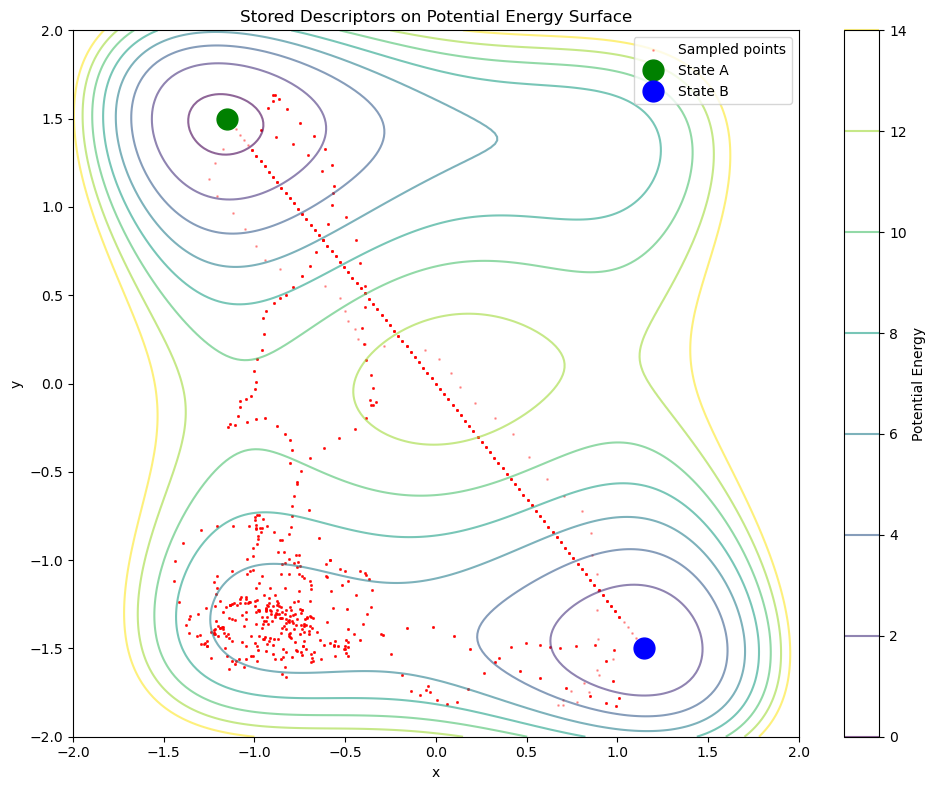

Total points stored: 3135


In [10]:
# Get all descriptors at interface 0.0
all_descriptors = desc_storage.get_interface_descriptors(
    set_name='TPS',
    interface_value=0.0,
    descriptor_names=['x_coord', 'y_coord'],
    starting_traj=0
)

x_coords = all_descriptors[:, 0]
y_coords = all_descriptors[:, 1]

# Plot potential surface with trajectories overlaid
pes = tps_setup.pes
x_grid = np.linspace(pes.extent[0], pes.extent[1], 200)
y_grid = np.linspace(pes.extent[2], pes.extent[3], 200)
X, Y, U = pes.plot_2d_pes(x_grid, y_grid)

fig, ax = plt.subplots(figsize=(10, 8))
contours = ax.contour(X, Y, U, levels=pes.levels, cmap='viridis', alpha=0.6)
plt.colorbar(contours, label='Potential Energy', ax=ax)

# Plot all stored trajectory points
ax.scatter(x_coords, y_coords, c='red', s=1, alpha=0.3, label='Sampled points')

# Mark states
ax.plot(pes.state_A[0], pes.state_A[1], 'go', markersize=15, label='State A')
ax.plot(pes.state_B[0], pes.state_B[1], 'bo', markersize=15, label='State B')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Stored Descriptors on Potential Energy Surface')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Total points stored: {len(x_coords)}")

## 10. Retrieve Individual Trajectory Descriptors

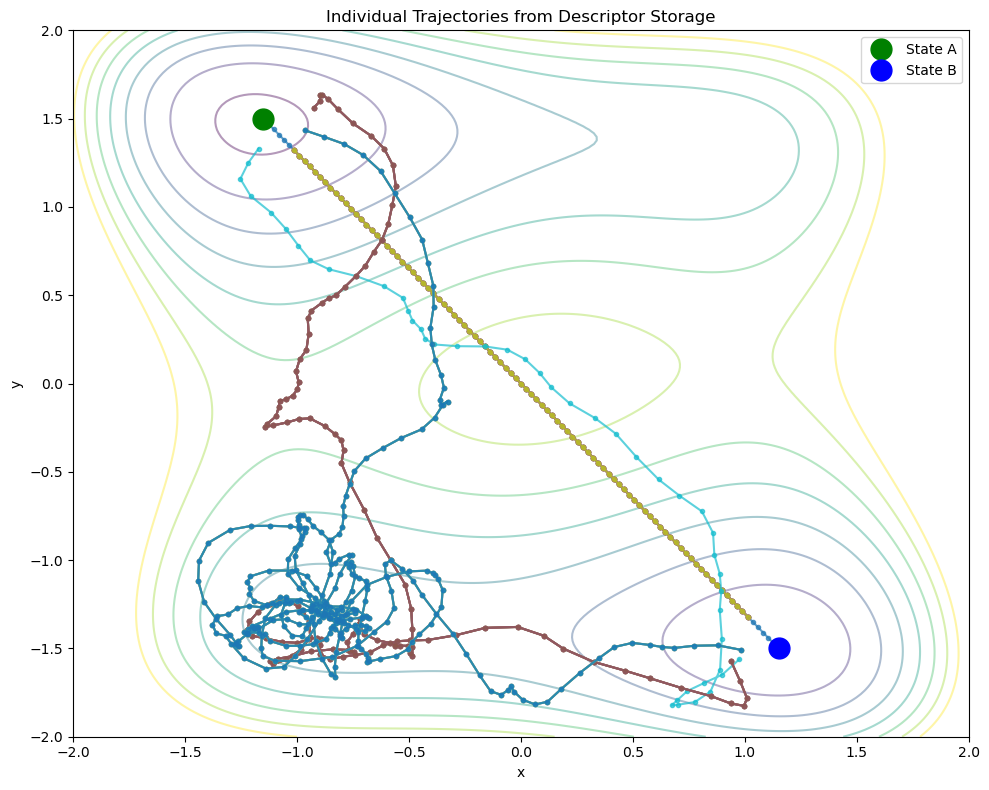

In [11]:
# Plot a few individual trajectories
fig, ax = plt.subplots(figsize=(10, 8))

# Plot potential surface
contours = ax.contour(X, Y, U, levels=pes.levels, cmap='viridis', alpha=0.4)

# Plot first 5 trajectories individually
n_trajs = len(desc_storage.sets['TPS'].interfaces['0.00'].trajectories)
for traj_idx in range(n_trajs):
    traj_desc = desc_storage.get_trajectory_descriptors(
        set_name='TPS',
        interface_value=0.0,
        trajectory_index=traj_idx,
        descriptor_names=['x_coord', 'y_coord']
    )
    ax.plot(traj_desc[:, 0], traj_desc[:, 1], '-o', markersize=3, 
            alpha=0.7)

# Mark states
ax.plot(pes.state_A[0], pes.state_A[1], 'go', markersize=15, label='State A', zorder=10)
ax.plot(pes.state_B[0], pes.state_B[1], 'bo', markersize=15, label='State B', zorder=10)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Individual Trajectories from Descriptor Storage')
ax.legend()
plt.tight_layout()
plt.show()

## 11. Test Alternative: Multi-dimensional CV

Demonstrate using a single CV that returns multiple values (like descriptor_transform functions).

In [12]:
# Define a multi-dimensional CV (like descriptor_transform functions)
def combined_cv(snapshot):
    """Returns both x and y in a single array."""
    return np.array([
        snapshot.coordinates[0][0],  # x
        snapshot.coordinates[0][1],  # y
    ])

cv_combined = paths.FunctionCV(
    name="xy_combined",
    f=combined_cv,
    cv_wrap_numpy_array=True,
    cv_scalarize_numpy_singletons=False
)

# Test on template
test_output = cv_combined(tps_setup.template)
print(f"Combined CV output shape: {test_output.shape}")
print(f"Combined CV output: {test_output}")

Combined CV output shape: (2,)
Combined CV output: [0.5 0.5]


In [13]:
# Example: Using the combined CV with automatic name inference
# This demonstrates how descriptor_transform functions would be handled

# descriptor_storage_path_multi = Path("storages/toy_descriptor_storage_multidim")

# The sampling_descriptor_manager will automatically:
# - Detect that cv_combined returns 2 values
# - Split them into separate named descriptors
# - Handle the shape transformations

# Uncomment to test:
# sampling_descriptor_manager(
#     descriptor_storage_path=descriptor_storage_path_multi,
#     sampler=sampler,
#     ops_storage=storage,
#     cv_functions=cv_combined,
#     descriptor_names=['x', 'y'],  # Explicit names for the 2 dimensions
#     n_steps=10,
#     increment_steps=5,
# )

# print("Multi-dimensional CV demo ready")

## 12. Clean Up

In [14]:
# Close storages
storage.close()
desc_storage.close()

print("Storages closed successfully!")
print(f"\nFiles created:")
print(f"  - OPS storage: {storage_file}")
print(f"  - Descriptor storage: {descriptor_storage_path}.meta.json")
print(f"  - Descriptor storage: {descriptor_storage_path}.descriptors.npz")
print(f"  - Descriptor storage: {descriptor_storage_path}.structure.json")

Storages closed successfully!

Files created:
  - OPS storage: storages/toy_tps_descriptor_test.nc
  - Descriptor storage: storages/toy_descriptor_storage_test.meta.json
  - Descriptor storage: storages/toy_descriptor_storage_test.descriptors.npz
  - Descriptor storage: storages/toy_descriptor_storage_test.structure.json
